In [71]:
import os
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [73]:
project_path = Path(
    r"C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance"
)

dataset_file = project_path / "results" / "complete_bearing_features.csv"

model_file = (
    project_path / "results" / "models" /
    "best_bearing_fault_model.pkl"
)

print("Dataset exists:", dataset_file.exists())
print("Model exists:", model_file.exists())

Dataset exists: True
Model exists: True


In [75]:
df = pd.read_csv(dataset_file)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (3183, 14)


,Mean,RMS,Standard_Deviation,Variance,Minimum,Maximum,Peak_to_Peak,Kurtosis,Skewness,Crest_Factor,Label,Window_ID,Source_File,Signal_ID
0,0.012005,0.073256,0.072266,0.005222,-0.272869,0.217794,0.490663,-0.045824,-0.137322,3.724845,Normal,0,Normal_0.mat,X097_DE_time
1,0.013116,0.074507,0.073344,0.005379,-0.272869,0.212370,0.485239,-0.116338,-0.010099,3.662321,Normal,1,Normal_0.mat,X097_DE_time
2,0.012790,0.079035,0.077993,0.006083,-0.226765,0.223010,0.449775,-0.184580,-0.062348,2.869171,Normal,2,Normal_0.mat,X097_DE_time
3,0.012148,0.077916,0.076964,0.005923,-0.226765,0.223010,0.449775,-0.150657,-0.103819,2.910361,Normal,3,Normal_0.mat,X097_DE_time
4,0.011959,0.074338,0.073370,0.005383,-0.202148,0.219255,0.421403,-0.221760,0.025960,2.949440,Normal,4,Normal_0.mat,X097_DE_time


In [77]:
print("Column names:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df["Label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nNumber of original recordings:")
print(df["Source_File"].nunique())

Column names:
['Mean', 'RMS', 'Standard_Deviation', 'Variance', 'Minimum', 'Maximum', 'Peak_to_Peak', 'Kurtosis', 'Skewness', 'Crest_Factor', 'Label', 'Window_ID', 'Source_File', 'Signal_ID']

Class distribution:
Label
Normal        2124
Outer_Race    1059
Name: count, dtype: int64

Missing values:
0

Number of original recordings:
13


In [79]:
best_model = joblib.load(model_file)

print("Saved model loaded successfully!")
print("Model type:", type(best_model))

Saved model loaded successfully!
Model type: <class 'sklearn.tree._classes.DecisionTreeClassifier'>


In [144]:
from pathlib import Path
import joblib

project_path = Path(
    r"C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance"
)

models_path = project_path / "results" / "models"

print("Model folder:", models_path)
print("Folder exists:", models_path.exists())

Model folder: C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\results\models
Folder exists: True


In [146]:
scaler_file = models_path / "bearing_feature_scaler.pkl"

scaler = joblib.load(scaler_file)

print("Scaler loaded successfully!")
print("Scaler features:", scaler.n_features_in_)

Scaler loaded successfully!
Scaler features: 10


In [81]:
print("Best model:")
print(best_model)

Best model:
DecisionTreeClassifier(class_weight='balanced', max_depth=8,
                       min_samples_split=10, random_state=42)


In [83]:
X = df[feature_columns].copy()

# Convert text labels into numeric labels
y = df["Label"].map({
    "Normal": 0,
    "Outer_Race": 1
})

groups = df["Source_File"].copy()

# Recreate original train/test split
test_recordings = [
    "Normal_0.mat",
    "0R007_12_0HP.mat",
    "0R007_12_1HP.mat"
]

test_mask = df["Source_File"].isin(test_recordings)
train_mask = ~test_mask

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

print("\nSaved model classes:", best_model.classes_)

Training samples: 2710
Testing samples: 473

Training labels:
Label
0    1887
1     823
Name: count, dtype: int64

Testing labels:
Label
0    237
1    236
Name: count, dtype: int64

Saved model classes: [0 1]


In [85]:
train_predictions = best_model.predict(X_train)

print("Training accuracy:",
      accuracy_score(y_train, train_predictions))

print("\nTraining prediction distribution:")
print(pd.Series(train_predictions).value_counts())

print("\nTraining classification report:")
print(classification_report(
    y_train,
    train_predictions,
    target_names=["Normal", "Outer_Race"]
))

Training accuracy: 0.303690036900369

Training prediction distribution:
1    2710
Name: count, dtype: int64

Training classification report:
              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00      1887
  Outer_Race       0.30      1.00      0.47       823

    accuracy                           0.30      2710
   macro avg       0.15      0.50      0.23      2710
weighted avg       0.09      0.30      0.14      2710



C:\Users\suthi\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\suthi\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\suthi\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [87]:
splitter = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

splits = list(
    splitter.split(X, y_encoded, groups)
)

print("Number of folds:", len(splits))

for fold, (train_idx, test_idx) in enumerate(splits):

    print(f"\nFOLD {fold + 1}")

    print("Training samples:", len(train_idx))
    print("Testing samples:", len(test_idx))

    print(
        "Training recordings:",
        groups.iloc[train_idx].nunique()
    )

    print(
        "Testing recordings:",
        groups.iloc[test_idx].nunique()
    )

    print(
        "Test class distribution:",
        y.iloc[test_idx].value_counts().to_dict()
    )

Number of folds: 4

FOLD 1
Training samples: 1650
Testing samples: 1533
Training recordings: 10
Testing recordings: 3
Test class distribution: {0: 1416, 1: 117}

FOLD 2
Training samples: 2712
Testing samples: 471
Training recordings: 9
Testing recordings: 4
Test class distribution: {1: 471}

FOLD 3
Training samples: 2476
Testing samples: 707
Training recordings: 10
Testing recordings: 3
Test class distribution: {0: 471, 1: 236}

FOLD 4
Training samples: 2711
Testing samples: 472
Training recordings: 10
Testing recordings: 3
Test class distribution: {0: 237, 1: 235}


In [89]:
for fold, (train_idx, test_idx) in enumerate(splits):

    if len(train_idx) == 2710 and len(test_idx) == 473:

        print("Matching fold found:", fold + 1)

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y_encoded.iloc[train_idx]
        y_test = y_encoded.iloc[test_idx]

        print("\nTraining shape:", X_train.shape)
        print("Testing shape:", X_test.shape)

        print("\nTraining labels:")
        print(y.iloc[train_idx].value_counts())

        print("\nTesting labels:")
        print(y.iloc[test_idx].value_counts())

        break

else:
    print("No matching fold found.")

No matching fold found.


In [91]:
# Select Fold 1
train_idx, test_idx = splits[0]

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y_encoded.iloc[train_idx]
y_test = y_encoded.iloc[test_idx]

print("Selected Fold: 1")

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y.iloc[train_idx].value_counts())

print("\nTesting class distribution:")
print(y.iloc[test_idx].value_counts())

print("\nTraining recordings:", groups.iloc[train_idx].nunique())
print("Testing recordings:", groups.iloc[test_idx].nunique())

Selected Fold: 1

Training samples: 1650
Testing samples: 1533

Training class distribution:
Label
1    942
0    708
Name: count, dtype: int64

Testing class distribution:
Label
0    1416
1     117
Name: count, dtype: int64

Training recordings: 10
Testing recordings: 3


In [93]:
test_recordings = [
    "Normal_0.mat",
    "0R007_12_0HP.mat",
    "0R007_12_1HP.mat"
]

test_mask = df["Source_File"].isin(test_recordings)
train_mask = ~test_mask

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y_encoded.loc[train_mask].copy()
y_test = y_encoded.loc[test_mask].copy()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining class distribution:")
print(y.loc[train_mask].value_counts())

print("\nTesting class distribution:")
print(y.loc[test_mask].value_counts())

Training shape: (2710, 10)
Testing shape: (473, 10)

Training class distribution:
Label
0    1887
1     823
Name: count, dtype: int64

Testing class distribution:
Label
0    237
1    236
Name: count, dtype: int64


In [95]:
train_groups = set(df.loc[train_mask, "Source_File"])
test_groups = set(df.loc[test_mask, "Source_File"])

print("Training recordings:", len(train_groups))
print("Testing recordings:", len(test_groups))

print("Common recordings:", train_groups.intersection(test_groups))

Training recordings: 10
Testing recordings: 3
Common recordings: set()


In [97]:
# Predict using the saved model
y_pred = best_model.predict(X_test)

print("Predictions generated successfully!")

print("Actual labels:", len(y_test))
print("Predicted labels:", len(y_pred))

print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated successfully!
Actual labels: 473
Predicted labels: 473

First 10 predictions:
[1 1 1 1 1 1 1 1 1 1]


In [99]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

balanced_acc = balanced_accuracy_score(y_test, y_pred)

print("DECISION TREE MODEL PERFORMANCE")
print("--------------------------------")

print(f"Accuracy:           {accuracy:.4f}")
print(f"Precision:          {precision:.4f}")
print(f"Recall:             {recall:.4f}")
print(f"F1 Score:           {f1:.4f}")
print(f"Balanced Accuracy:  {balanced_acc:.4f}")

DECISION TREE MODEL PERFORMANCE
--------------------------------
Accuracy:           0.4989
Precision:          0.4989
Recall:             1.0000
F1 Score:           0.6657
Balanced Accuracy:  0.5000


In [101]:
# Clasification report
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Normal", "Outer Race"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00       237
  Outer Race       0.50      1.00      0.67       236

    accuracy                           0.50       473
   macro avg       0.25      0.50      0.33       473
weighted avg       0.25      0.50      0.33       473



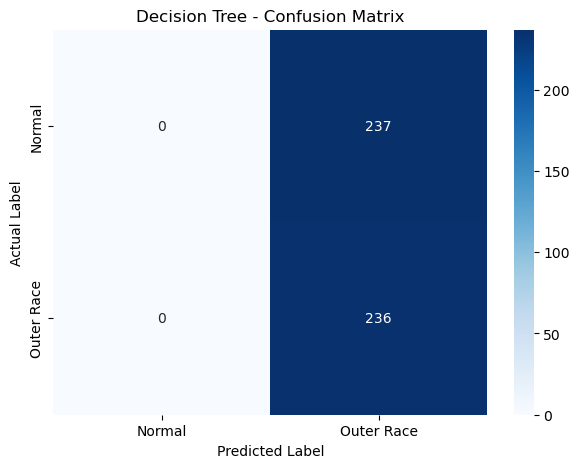

In [103]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Outer Race"],
    yticklabels=["Normal", "Outer Race"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree - Confusion Matrix")

plt.show()

In [105]:
y_probability = best_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.5


In [107]:
print("Model classes:", best_model.classes_)

print("\nActual test distribution:")
print(pd.Series(y_test).value_counts())

print("\nPredicted test distribution:")
print(pd.Series(y_pred).value_counts())

print("\nModel feature names:")
print(best_model.feature_names_in_)

Model classes: [0 1]

Actual test distribution:
Label
0    237
1    236
Name: count, dtype: int64

Predicted test distribution:
1    473
Name: count, dtype: int64

Model feature names:
['Mean' 'RMS' 'Standard_Deviation' 'Variance' 'Minimum' 'Maximum'
 'Peak_to_Peak' 'Kurtosis' 'Skewness' 'Crest_Factor']


In [109]:
probabilities = best_model.predict_proba(X_test)

probability_df = pd.DataFrame(
    probabilities,
    columns=[
        f"Class_{c}" for c in best_model.classes_
    ]
)

print(probability_df.head(10))

print("\nProbability summary:")
print(probability_df.describe())

   Class_0  Class_1
0      0.0      1.0
1      0.0      1.0
2      0.0      1.0
3      0.0      1.0
4      0.0      1.0
5      0.0      1.0
6      0.0      1.0
7      0.0      1.0
8      0.0      1.0
9      0.0      1.0

Probability summary:
       Class_0  Class_1
count    473.0    473.0
mean       0.0      1.0
std        0.0      0.0
min        0.0      1.0
25%        0.0      1.0
50%        0.0      1.0
75%        0.0      1.0
max        0.0      1.0


In [111]:
y_train_pred = best_model.predict(X_train)

print("TRAINING PERFORMANCE")
print("---------------------")

print(
    classification_report(
        y_train,
        y_train_pred,
        labels=[0, 1],
        target_names=["Normal", "Outer Race"],
        zero_division=0
    )
)

print("Training accuracy:",
      accuracy_score(y_train, y_train_pred))

TRAINING PERFORMANCE
---------------------
              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00      1887
  Outer Race       0.30      1.00      0.47       823

    accuracy                           0.30      2710
   macro avg       0.15      0.50      0.23      2710
weighted avg       0.09      0.30      0.14      2710

Training accuracy: 0.303690036900369


In [113]:
print("Model parameters:")
print(best_model.get_params())

print("\nModel classes:")
print(best_model.classes_)

print("\nTree depth:")
print(best_model.get_depth())

print("\nNumber of leaves:")
print(best_model.get_n_leaves())

print("\nFeature importances:")
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": best_model.feature_importances_
})

print(importance_df.sort_values(
    by="Importance",
    ascending=False
))

Model parameters:
{'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}

Model classes:
[0 1]

Tree depth:
2

Number of leaves:
3

Feature importances:
              Feature    Importance
4             Minimum  1.000000e+00
2  Standard_Deviation  1.298961e-13
0                Mean  0.000000e+00
1                 RMS  0.000000e+00
3            Variance  0.000000e+00
5             Maximum  0.000000e+00
6        Peak_to_Peak  0.000000e+00
7            Kurtosis  0.000000e+00
8            Skewness  0.000000e+00
9        Crest_Factor  0.000000e+00


In [115]:
print("Root node class distribution:")
print(best_model.tree_.value[0])

print("\nRoot node sample count:")
print(best_model.tree_.n_node_samples[0])

print("\nWeighted root node sample count:")
print(best_model.tree_.weighted_n_node_samples[0])

Root node class distribution:
[[0.5 0.5]]

Root node sample count:
2710

Weighted root node sample count:
2710.0000000000896


In [117]:
print("Saved model classes:")
print(best_model.classes_)

print("\nTraining labels:")
print(y_train.unique())

print("\nTesting labels:")
print(y_test.unique())

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Saved model classes:
[0 1]

Training labels:
[0 1]

Testing labels:
[0 1]

Training label distribution:
Label
0    1887
1     823
Name: count, dtype: int64

Testing label distribution:
Label
0    237
1    236
Name: count, dtype: int64


In [122]:
print("Model feature names:")
print(best_model.feature_names_in_)

print("\nNotebook 06 feature columns:")
print(X_train.columns.tolist())

print("\nAre the feature columns in the same order?")
print(list(best_model.feature_names_in_) == X_train.columns.tolist())

Model feature names:
['Mean' 'RMS' 'Standard_Deviation' 'Variance' 'Minimum' 'Maximum'
 'Peak_to_Peak' 'Kurtosis' 'Skewness' 'Crest_Factor']

Notebook 06 feature columns:
['Mean', 'RMS', 'Standard_Deviation', 'Variance', 'Minimum', 'Maximum', 'Peak_to_Peak', 'Kurtosis', 'Skewness', 'Crest_Factor']

Are the feature columns in the same order?
True


In [124]:
print("Model expected number of features:",
      best_model.n_features_in_)

print("Notebook 06 number of features:",
      X_train.shape[1])

print("\nNotebook 06 feature summary:")
print(X_train.describe().round(4))

Model expected number of features: 10
Notebook 06 number of features: 10

Notebook 06 feature summary:
            Mean        RMS  Standard_Deviation   Variance    Minimum  \
count  2710.0000  2710.0000           2710.0000  2710.0000  2710.0000   
mean      0.0138     0.2264              0.2253     0.1199    -1.0836   
std       0.0120     0.2626              0.2629     0.2095     1.4154   
min       0.0026     0.0598              0.0586     0.0034    -6.4117   
25%       0.0092     0.0648              0.0636     0.0040    -2.6989   
50%       0.0118     0.0669              0.0657     0.0043    -0.2155   
75%       0.0142     0.3716              0.3673     0.1349    -0.1967   
max       0.0934     0.8740              0.8740     0.7639    -0.1512   

         Maximum  Peak_to_Peak   Kurtosis   Skewness  Crest_Factor  
count  2710.0000     2710.0000  2710.0000  2710.0000     2710.0000  
mean      1.1476        2.2312     2.7258    -0.1087        4.1439  
std       1.5124        2.9243  

In [126]:
print("Notebook 05 training shape:", X_train.shape)

print("\nFirst 5 training rows:")
print(X_train.head())

print("\nTraining feature means:")
print(X_train.mean())

Notebook 05 training shape: (2710, 10)

First 5 training rows:
         Mean       RMS  Standard_Deviation  Variance   Minimum   Maximum  \
237  0.008002  0.066925            0.066445  0.004415 -0.198810  0.204234   
238  0.010276  0.065848            0.065041  0.004230 -0.197350  0.204443   
239  0.009596  0.063714            0.062987  0.003967 -0.197350  0.204443   
240  0.009945  0.064412            0.063640  0.004050 -0.182330  0.204860   
241  0.010816  0.063972            0.063052  0.003975 -0.180244  0.211327   

     Peak_to_Peak  Kurtosis  Skewness  Crest_Factor  
237      0.403045 -0.180225 -0.277955      3.051702  
238      0.401793 -0.086259 -0.225813      3.104787  
239      0.401793 -0.016090 -0.272366      3.208751  
240      0.387190 -0.191945 -0.200513      3.180459  
241      0.391571 -0.193607 -0.210519      3.303413  

Training feature means:
Mean                  0.013768
RMS                   0.226407
Standard_Deviation    0.225278
Variance              0.119859
M

In [128]:
print("Loaded model training accuracy:",
      best_model.score(X_train, y_train))

print("\nPredictions:")
print(pd.Series(best_model.predict(X_train)).value_counts())

print("\nModel tree:")
print(best_model.tree_.feature)
print(best_model.tree_.threshold)

Loaded model training accuracy: 0.303690036900369

Predictions:
1    2710
Name: count, dtype: int64

Model tree:
[ 4 -2  2 -2 -2]
[ 0.17840053 -2.         -0.63364783 -2.         -2.        ]


In [130]:
print("LOADED MODEL")
print("Tree features:", best_model.tree_.feature)
print("Tree thresholds:", best_model.tree_.threshold)
print("Tree values:")
print(best_model.tree_.value)

LOADED MODEL
Tree features: [ 4 -2  2 -2 -2]
Tree thresholds: [ 0.17840053 -2.         -0.63364783 -2.         -2.        ]
Tree values:
[[[0.5 0.5]]

 [[0.  1. ]]

 [[1.  0. ]]

 [[1.  0. ]]

 [[1.  0. ]]]


In [132]:
print("Feature used at root:",
      feature_columns[best_model.tree_.feature[0]])

print("Root threshold:",
      best_model.tree_.threshold[0])

print("\nMinimum feature range:")
print(X_train["Minimum"].min())
print(X_train["Minimum"].max())

Feature used at root: Minimum
Root threshold: 0.17840053141117096

Minimum feature range:
-6.411720658682635
-0.1512461538461538


In [134]:
print("Notebook 05:")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nFirst 10 Minimum values:")
print(X_train["Minimum"].head(10).tolist())

print("\nFirst 10 labels:")
print(y_train.head(10).tolist())

print("\nIndex alignment:")
print(X_train.index.equals(y_train.index))

Notebook 05:
X_train shape: (2710, 10)
y_train shape: (2710,)

First 10 Minimum values:
[-0.1988104615384615, -0.1973501538461538, -0.1973501538461538, -0.1823298461538461, -0.1802436923076923, -0.1846246153846154, -0.1967243076923076, -0.1967243076923076, -0.2278079999999999, -0.2278079999999999]

First 10 labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Index alignment:
True


In [136]:
left_branch = X_train["Minimum"] <= best_model.tree_.threshold[0]

print("Left branch samples:", left_branch.sum())
print("Right branch samples:", (~left_branch).sum())

print("\nActual labels in left branch:")
print(y_train[left_branch].value_counts())

print("\nActual labels in right branch:")
print(y_train[~left_branch].value_counts())

Left branch samples: 2710
Right branch samples: 0

Actual labels in left branch:
Label
0    1887
1     823
Name: count, dtype: int64

Actual labels in right branch:
Series([], Name: count, dtype: int64)


In [138]:
print("Notebook 05 feature statistics:")
print(X_train[["Mean", "RMS", "Minimum", "Maximum"]].describe())

Notebook 05 feature statistics:
              Mean          RMS      Minimum      Maximum
count  2710.000000  2710.000000  2710.000000  2710.000000
mean      0.013768     0.226407    -1.083593     1.147614
std       0.012016     0.262599     1.415414     1.512382
min       0.002572     0.059770    -6.411721     0.157296
25%       0.009207     0.064800    -2.698860     0.198185
50%       0.011825     0.066892    -0.215500     0.216438
75%       0.014223     0.371637    -0.196724     2.770737
max       0.093418     0.874031    -0.151246     6.652937


In [140]:
print("CSV file used:")
print(csv_path)

print("\nFirst 5 dataset rows:")
print(df[["Source_File", "Label", "Minimum", "Maximum"]].head())

CSV file used:


NameError: name 'csv_path' is not defined

In [148]:
X_train_scaled = pd.DataFrame(
    scaler.transform(X_train),
    columns=feature_columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=feature_columns,
    index=X_test.index
)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (2710, 10)
Testing shape: (473, 10)


In [150]:
from sklearn.metrics import accuracy_score, classification_report

train_predictions = best_model.predict(X_train_scaled)

print("Training Accuracy:",
      accuracy_score(y_train, train_predictions))

print("\nClassification Report:")
print(classification_report(
    y_train,
    train_predictions,
    target_names=["Normal", "Outer_Race"]
))

Training Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      1887
  Outer_Race       1.00      1.00      1.00       823

    accuracy                           1.00      2710
   macro avg       1.00      1.00      1.00      2710
weighted avg       1.00      1.00      1.00      2710



TEST ACCURACY: 1.0

BALANCED ACCURACY: 1.0

ROC-AUC: 1.0

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       237
  Outer_Race       1.00      1.00      1.00       236

    accuracy                           1.00       473
   macro avg       1.00      1.00      1.00       473
weighted avg       1.00      1.00      1.00       473



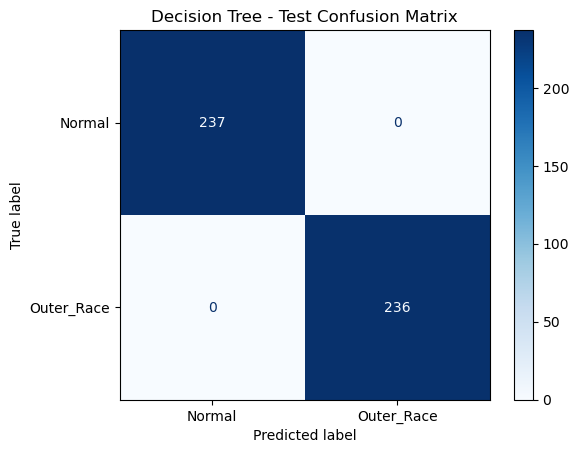

In [152]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    roc_auc_score
)
import matplotlib.pyplot as plt

# Predict unseen test data
test_predictions = best_model.predict(X_test_scaled)

# Calculate probabilities
test_probabilities = best_model.predict_proba(X_test_scaled)[:, 1]

# Evaluation metrics
print("TEST ACCURACY:",
      accuracy_score(y_test, test_predictions))

print("\nBALANCED ACCURACY:",
      balanced_accuracy_score(y_test, test_predictions))

print("\nROC-AUC:",
      roc_auc_score(y_test, test_probabilities))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Normal", "Outer_Race"]
))

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Outer_Race"]
)

display.plot(cmap="Blues")
plt.title("Decision Tree - Test Confusion Matrix")
plt.show()

              Feature    Importance
4             Minimum  1.000000e+00
2  Standard_Deviation  1.298961e-13
0                Mean  0.000000e+00
1                 RMS  0.000000e+00
3            Variance  0.000000e+00
5             Maximum  0.000000e+00
6        Peak_to_Peak  0.000000e+00
7            Kurtosis  0.000000e+00
8            Skewness  0.000000e+00
9        Crest_Factor  0.000000e+00


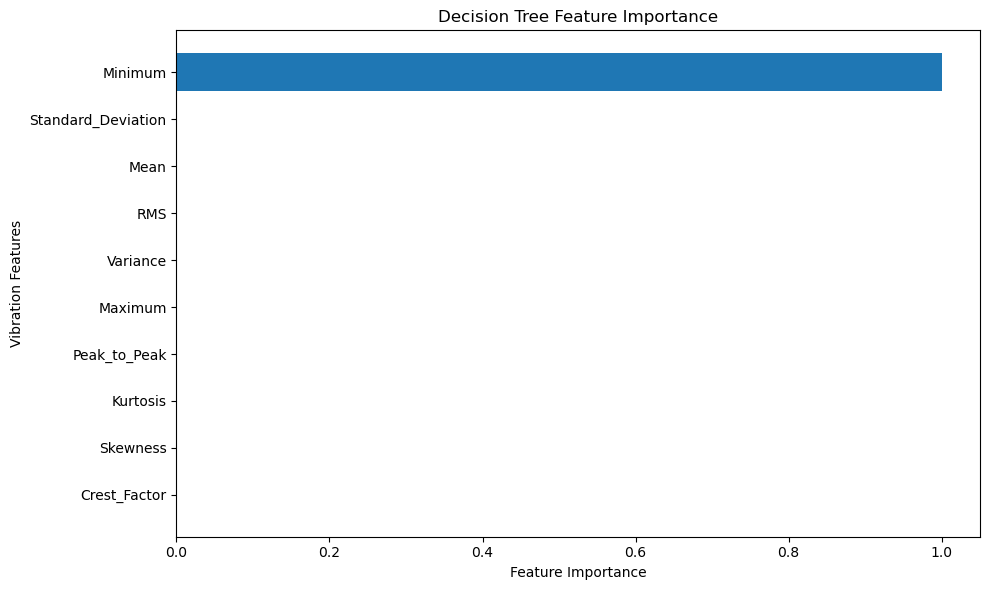

In [154]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Vibration Features")
plt.title("Decision Tree Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

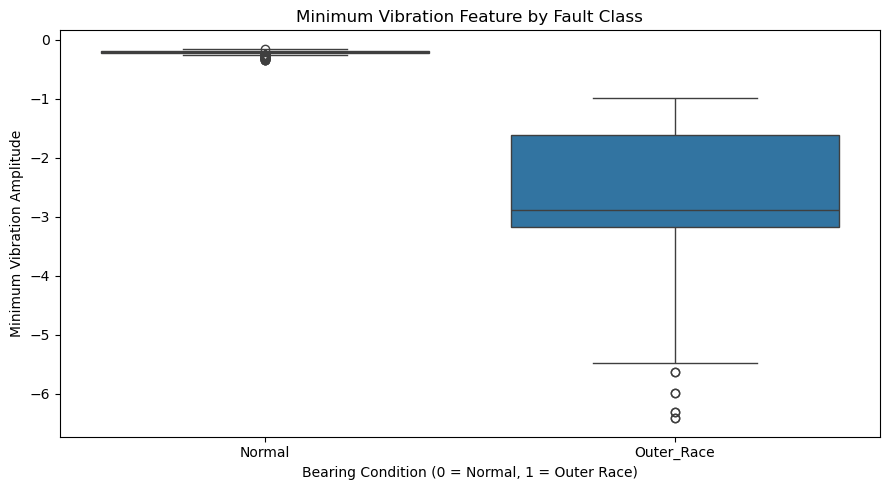

In [156]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Label",
    y="Minimum"
)

plt.title("Minimum Vibration Feature by Fault Class")
plt.xlabel("Bearing Condition (0 = Normal, 1 = Outer Race)")
plt.ylabel("Minimum Vibration Amplitude")

plt.tight_layout()
plt.show()

In [158]:
print(
    df.groupby("Label")["Minimum"]
    .describe()
    .round(4)
)

             count    mean     std     min     25%     50%     75%     max
Label                                                                     
Normal      2124.0 -0.2070  0.0230 -0.3459 -0.2186 -0.2041 -0.1919 -0.1512
Outer_Race  1059.0 -2.7103  1.0647 -6.4117 -3.1709 -2.8804 -1.6156 -0.9816


In [160]:
print(
    df.groupby(["Source_File", "Label"])["Minimum"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(4)
)

                             count    mean     std     min     max
Source_File      Label                                            
0R007_12_0HP.mat Outer_Race    118 -1.3584  0.1881 -1.7627 -1.0571
0R007_12_1HP.mat Outer_Race    118 -1.3759  0.2156 -2.0400 -0.9816
0R007_3_0HP.mat  Outer_Race    118 -2.8528  0.1285 -3.2601 -2.4788
0R007_3_1HP.mat  Outer_Race    117 -3.0318  0.1121 -3.3060 -2.7642
0R007_6_0HP.mat  Outer_Race    118 -3.0575  0.1396 -3.4087 -2.7196
0R007_6_1HP.mat  Outer_Race    118 -2.8168  0.0943 -3.0120 -2.5815
0R021_12_0HP.mat Outer_Race    117 -3.6964  0.3024 -4.3537 -2.9916
0R021_6_0HP.mat  Outer_Race    118 -4.5794  0.6552 -6.4117 -3.3027
Normal_0.mat     Normal        237 -0.2144  0.0202 -0.2866 -0.1788
Normal_1.mat     Normal        471 -0.2071  0.0236 -0.3459 -0.1602
Normal_2.mat     Normal        943 -0.2051  0.0236 -0.3459 -0.1512
Normal_3.mat     Normal        473 -0.2073  0.0219 -0.3065 -0.1681
OR021_3_0HP.mat  Outer_Race    117 -1.6260  0.1571 -1.9794 -1.

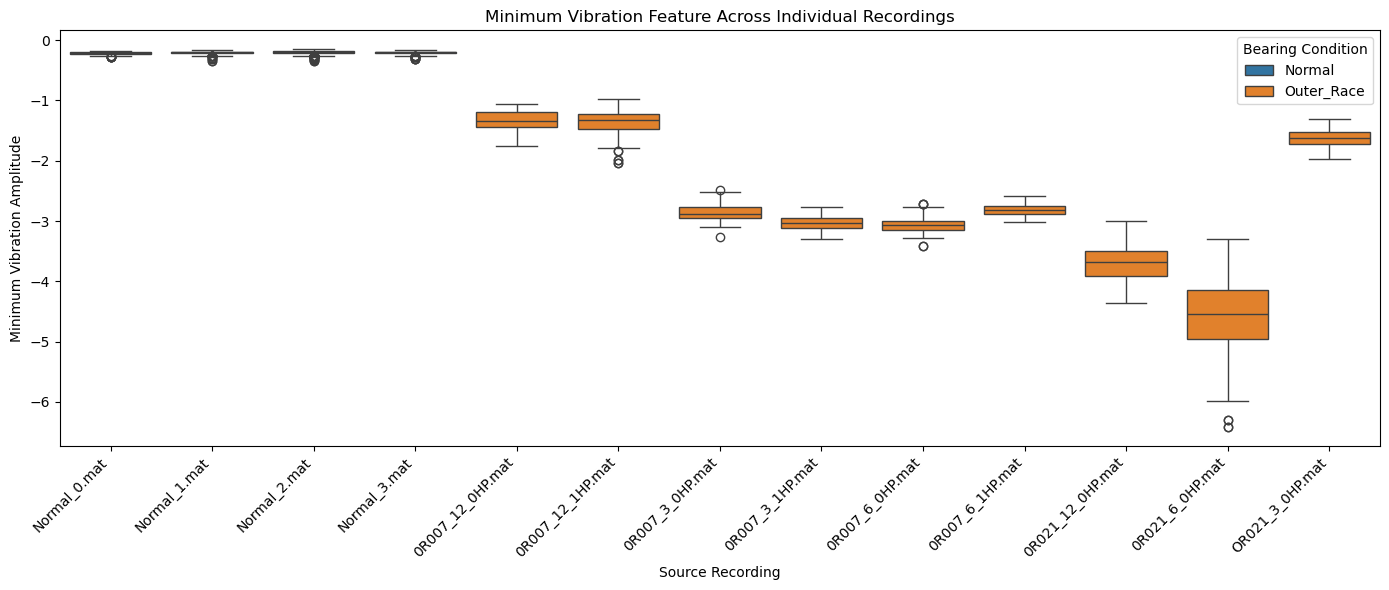

In [162]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="Source_File",
    y="Minimum",
    hue="Label"
)

plt.title("Minimum Vibration Feature Across Individual Recordings")
plt.xlabel("Source Recording")
plt.ylabel("Minimum Vibration Amplitude")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Bearing Condition")
plt.tight_layout()
plt.show()

In [164]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Prepare features and labels
X = df[feature_columns].copy()

y = df["Label"].map({
    "Normal": 0,
    "Outer_Race": 1
})

groups = df["Source_File"]

# Create grouped cross-validation
group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Build pipeline: scaling + Decision Tree
cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=8,
        min_samples_split=10,
        random_state=42
    ))
])

print("Total samples:", len(X))
print("Total source recordings:", groups.nunique())
print("\nClass distribution:")
print(y.value_counts().rename(index={
    0: "Normal",
    1: "Outer_Race"
}))

Total samples: 3183
Total source recordings: 13

Class distribution:
Label
Normal        2124
Outer_Race    1059
Name: count, dtype: int64


In [166]:
for fold, (train_idx, test_idx) in enumerate(
    group_cv.split(X, y, groups),
    start=1
):
    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    print(f"\nFOLD {fold}")
    print("-" * 40)

    print("Training samples:", len(train_idx))
    print("Testing samples:", len(test_idx))

    print("Training recordings:", len(train_groups))
    print("Testing recordings:", len(test_groups))

    print("Training classes:")
    print(y.iloc[train_idx].value_counts().to_dict())

    print("Testing classes:")
    print(y.iloc[test_idx].value_counts().to_dict())

    print("Recording overlap:", train_groups.intersection(test_groups))


FOLD 1
----------------------------------------
Training samples: 2831
Testing samples: 352
Training recordings: 10
Testing recordings: 3
Training classes:
{0: 2124, 1: 707}
Testing classes:
{1: 352}
Recording overlap: set()

FOLD 2
----------------------------------------
Training samples: 2474
Testing samples: 709
Training recordings: 10
Testing recordings: 3
Training classes:
{0: 1651, 1: 823}
Testing classes:
{0: 473, 1: 236}
Recording overlap: set()

FOLD 3
----------------------------------------
Training samples: 2003
Testing samples: 1180
Training recordings: 11
Testing recordings: 2
Training classes:
{1: 1059, 0: 944}
Testing classes:
{0: 1180}
Recording overlap: set()

FOLD 4
----------------------------------------
Training samples: 2830
Testing samples: 353
Training recordings: 10
Testing recordings: 3
Training classes:
{0: 2124, 1: 706}
Testing classes:
{1: 353}
Recording overlap: set()

FOLD 5
----------------------------------------
Training samples: 2594
Testing sample

In [168]:
group_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, test_idx) in enumerate(
    group_cv.split(X, y, groups),
    start=1
):
    print(f"\nFOLD {fold}")
    print("-" * 40)

    print("Training recordings:",
          groups.iloc[train_idx].nunique())

    print("Testing recordings:",
          groups.iloc[test_idx].nunique())

    print("Testing class distribution:")
    print(y.iloc[test_idx].value_counts().to_dict())

    print("Recording overlap:",
          set(groups.iloc[train_idx]) &
          set(groups.iloc[test_idx]))


FOLD 1
----------------------------------------
Training recordings: 10
Testing recordings: 3
Testing class distribution:
{0: 1416, 1: 117}
Recording overlap: set()

FOLD 2
----------------------------------------
Training recordings: 9
Testing recordings: 4
Testing class distribution:
{1: 471}
Recording overlap: set()

FOLD 3
----------------------------------------
Training recordings: 10
Testing recordings: 3
Testing class distribution:
{0: 471, 1: 236}
Recording overlap: set()

FOLD 4
----------------------------------------
Training recordings: 10
Testing recordings: 3
Testing class distribution:
{0: 237, 1: 235}
Recording overlap: set()


In [170]:
from sklearn.model_selection import LeaveOneGroupOut

logo = LeaveOneGroupOut()

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups),
    start=1
):
    print(f"\nFOLD {fold}")
    print("Held-out recording:",
          groups.iloc[test_idx].unique()[0])

    print("Training classes:",
          y.iloc[train_idx].value_counts().to_dict())

    print("Testing classes:",
          y.iloc[test_idx].value_counts().to_dict())

    print("Recording overlap:",
          set(groups.iloc[train_idx]) &
          set(groups.iloc[test_idx]))


FOLD 1
Held-out recording: 0R007_12_0HP.mat
Training classes: {0: 2124, 1: 941}
Testing classes: {1: 118}
Recording overlap: set()

FOLD 2
Held-out recording: 0R007_12_1HP.mat
Training classes: {0: 2124, 1: 941}
Testing classes: {1: 118}
Recording overlap: set()

FOLD 3
Held-out recording: 0R007_3_0HP.mat
Training classes: {0: 2124, 1: 941}
Testing classes: {1: 118}
Recording overlap: set()

FOLD 4
Held-out recording: 0R007_3_1HP.mat
Training classes: {0: 2124, 1: 942}
Testing classes: {1: 117}
Recording overlap: set()

FOLD 5
Held-out recording: 0R007_6_0HP.mat
Training classes: {0: 2124, 1: 941}
Testing classes: {1: 118}
Recording overlap: set()

FOLD 6
Held-out recording: 0R007_6_1HP.mat
Training classes: {0: 2124, 1: 941}
Testing classes: {1: 118}
Recording overlap: set()

FOLD 7
Held-out recording: 0R021_12_0HP.mat
Training classes: {0: 2124, 1: 942}
Testing classes: {1: 117}
Recording overlap: set()

FOLD 8
Held-out recording: 0R021_6_0HP.mat
Training classes: {0: 2124, 1: 941}


In [174]:
from IPython.display import display as show_table

show_table(fold_df.round(4))

,Fold,Source_File,Test_Samples,Accuracy,Precision,Recall,F1_Score
0,1,0R007_12_0HP.mat,118,1.0,1.0,1.0,1.0
1,2,0R007_12_1HP.mat,118,1.0,1.0,1.0,1.0
2,3,0R007_3_0HP.mat,118,1.0,1.0,1.0,1.0
3,4,0R007_3_1HP.mat,117,1.0,1.0,1.0,1.0
4,5,0R007_6_0HP.mat,118,1.0,1.0,1.0,1.0
5,6,0R007_6_1HP.mat,118,1.0,1.0,1.0,1.0
6,7,0R021_12_0HP.mat,117,1.0,1.0,1.0,1.0
7,8,0R021_6_0HP.mat,118,1.0,1.0,1.0,1.0
8,9,Normal_0.mat,237,1.0,0.0,0.0,0.0
9,10,Normal_1.mat,471,1.0,0.0,0.0,0.0


In [176]:
print("\nOVERALL LOGO CLASSIFICATION REPORT")

print(classification_report(
    all_actual,
    all_predicted,
    target_names=["Normal", "Outer_Race"],
    zero_division=0
))

print("Overall Confusion Matrix:")
print(confusion_matrix(all_actual, all_predicted))

print(
    "Overall Accuracy:",
    round(accuracy_score(all_actual, all_predicted), 4)
)


OVERALL LOGO CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      2124
  Outer_Race       1.00      1.00      1.00      1059

    accuracy                           1.00      3183
   macro avg       1.00      1.00      1.00      3183
weighted avg       1.00      1.00      1.00      3183

Overall Confusion Matrix:
[[2124    0]
 [   0 1059]]
Overall Accuracy: 1.0


In [178]:
results_df = pd.DataFrame({
    "Source_File": groups.reset_index(drop=True),
    "Actual": np.array(all_actual),
    "Predicted": np.array(all_predicted)
})

recording_check = (
    results_df
    .groupby("Source_File")
    .apply(
        lambda g: pd.Series({
            "Total_Windows": len(g),
            "Correct": (g["Actual"] == g["Predicted"]).sum(),
            "Incorrect": (g["Actual"] != g["Predicted"]).sum(),
            "Accuracy": accuracy_score(
                g["Actual"], g["Predicted"]
            )
        }),
        include_groups=False
    )
)

print(recording_check.round(4))

                  Total_Windows  Correct  Incorrect  Accuracy
Source_File                                                  
0R007_12_0HP.mat          118.0    118.0        0.0       1.0
0R007_12_1HP.mat          118.0    118.0        0.0       1.0
0R007_3_0HP.mat           118.0    118.0        0.0       1.0
0R007_3_1HP.mat           117.0    117.0        0.0       1.0
0R007_6_0HP.mat           118.0    118.0        0.0       1.0
0R007_6_1HP.mat           118.0    118.0        0.0       1.0
0R021_12_0HP.mat          117.0    117.0        0.0       1.0
0R021_6_0HP.mat           118.0    118.0        0.0       1.0
Normal_0.mat              237.0    237.0        0.0       1.0
Normal_1.mat              471.0    471.0        0.0       1.0
Normal_2.mat              943.0    943.0        0.0       1.0
Normal_3.mat              473.0    473.0        0.0       1.0
OR021_3_0HP.mat           117.0    117.0        0.0       1.0
